# F3 – Prévision de l'inflation

**Nom et prénom :** Oumaima Zaaiter    **Code Apogée :** 23009108    **Groupe :** G3    **Filière :** S7 FIN    **Date :** 2026-11-17

**Dépôt GitHub :** https://github.com/zaaiter-oumaima/23009108-Zaaiter-G3

## 1. Sujet et problématique
- **Intérêt du sujet** : anticiper l'inflation du mois suivant sert à une banque ou à un trésorier d'entreprise pour ajuster ses prévisions de coûts, ses clauses d'indexation ou ses anticipations de taux, et à un investisseur pour arbitrer entre actifs nominaux et réels. Un modèle utile est un modèle qui fait mieux qu'une règle simple, pas un modèle qui « devine » la bourse ou les prix.
- **Problématique** : l'inflation mensuelle américaine (variation de l'IPC CPIAUCSL d'un mois sur l'autre) de chacun des 24 derniers mois peut-elle être prévue, à partir de ses propres valeurs passées, avec une erreur plus faible que celle de la règle « inflation du mois précédent » ?
- **Objectif mesurable (fixé avant de voir les résultats de test)** : métrique principale = MAE (erreur absolue moyenne, en points de %) ; référence = dernière valeur observée (marche aléatoire) ; période de test = les 24 derniers mois de la série (novembre 2024 à octobre 2026) ; seuil de réussite = MAE du modèle inférieure d'au moins 5 % à celle de la référence.
- **Nature du problème** : régression sur série temporelle mensuelle, car la variable à prédire (l'inflation en %) est numérique et continue, et les observations sont ordonnées dans le temps (horizon de prévision : 1 mois).
- **Algorithme principal** : n° 2, régression Ridge (régression linéaire avec pénalité L2), un seul algorithme principal retenu parmi les 29 du support.

---
*Ce notebook suit le plan imposé en 10 sections. Les cellules de code sont suivies d'une cellule de texte qui interprète le résultat.*

### Configuration
Imports, graine aléatoire (`GRAINE = 42`), chemins relatifs et versions des bibliothèques.

In [1]:
import warnings, sys, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
GRAINE = 42
random.seed(GRAINE); np.random.seed(GRAINE)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

# Chemins relatifs : le notebook est dans notebooks/, les données dans data/raw/
RACINE = Path("..") if Path("../data/raw").exists() else Path(".")
DATA = RACINE / "data" / "raw" / "CPIAUCSL.csv"
if not DATA.exists():            # repli : fichier déposé à côté du notebook (ex. Colab)
    DATA = Path("CPIAUCSL.csv")
FIG = RACINE / "figures"; FIG.mkdir(exist_ok=True)
PROC = RACINE / "data" / "processed"; PROC.mkdir(parents=True, exist_ok=True)

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)
print("Fichier de données :", DATA)

Python 3.12.3 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2
Fichier de données : ../data/raw/CPIAUCSL.csv


## 2. Jeu de données

### 2.1 Chargement et vérification
Le fichier brut `CPIAUCSL.csv` (téléchargé depuis FRED) est lu depuis `data/raw/`. On vérifie les dimensions, les types, les premières et dernières lignes, la plage de dates et la fréquence.

In [2]:
brut = pd.read_csv(DATA, parse_dates=["observation_date"]).rename(columns={"observation_date": "DATE"})
n_brut, n_var_brut = brut.shape
d_deb, d_fin = brut["DATE"].min(), brut["DATE"].max()

print("Dimensions :", brut.shape)
print("\nTypes des variables :"); print(brut.dtypes)
print("\nPremières lignes :"); display(brut.head())
print("\nDernières lignes :"); display(brut.tail())
print("Plage de dates :", d_deb.date(), "->", d_fin.date())
print("Fréquence inférée par pandas :", pd.infer_freq(brut["DATE"]), "(MS = mensuelle, début de mois)")

Dimensions : (958, 2)

Types des variables :
DATE        datetime64[us]
CPIAUCSL           float64
dtype: object

Premières lignes :


,DATE,CPIAUCSL
0,1947-01-01,21.48
1,1947-02-01,21.62
2,1947-03-01,22.00
3,1947-04-01,22.00
4,1947-05-01,21.95



Dernières lignes :


,DATE,CPIAUCSL
953,2026-06-01,332.568
954,2026-07-01,332.813
955,2026-08-01,334.131
956,2026-09-01,336.298
957,2026-10-01,337.476


Plage de dates : 1947-01-01 -> 2026-10-01
Fréquence inférée par pandas : MS (MS = mensuelle, début de mois)


### 2.2 Description du jeu de données
- **Source exacte :** Federal Reserve Economic Data (FRED), Federal Reserve Bank of St. Louis. Série `CPIAUCSL` : *Consumer Price Index for All Urban Consumers: All Items in U.S. City Average*, produite par le U.S. Bureau of Labor Statistics (BLS), désaisonnalisée.
- **Lien d'accès :** https://fred.stlouisfed.org/series/CPIAUCSL
- **Date d'extraction :** 17 novembre 2026 (série mise à jour en continu : cette date permet de retrouver les mêmes chiffres).
- **Conditions d'utilisation :** la page FRED classe la série « public domain: citation requested » (domaine public, citation demandée). Citation : U.S. Bureau of Labor Statistics, *Consumer Price Index for All Urban Consumers: All Items in U.S. City Average [CPIAUCSL]*, retrieved from FRED, Federal Reserve Bank of St. Louis.
- **Taille :** 958 observations et 2 variables brutes (date et indice), du 1947-01 au 2026-10, fréquence **mensuelle**. Après construction des variables : 945 mois utilisables (de 1948-02 à 2026-10).
- **Unité d'observation :** un mois calendaire (une ligne = un mois, indice des prix moyen des États-Unis).
- **Variable cible :** `INFLATION`, variation en % de l'IPC par rapport au mois précédent : $\text{INFLATION}_t = \dfrac{CPI_t - CPI_{t-1}}{CPI_{t-1}} \times 100$. Elle est prévue à l'horizon d'un mois à partir des mois $t-1, t-2, \dots$
- **Adéquation avec la problématique :** une série mensuelle longue de l'IPC permet de mesurer l'inertie de l'inflation (autocorrélation) et de tester un modèle sur un vrai futur (les 24 derniers mois), ce qui répond directement à la question posée.

**Dictionnaire des variables**

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| `DATE` | Premier jour du mois observé | date | AAAA-MM-JJ | date (index) | 0 |
| `CPIAUCSL` | IPC brut du fichier FRED | numérique | indice (1982-1984 = 100) | brute | 0.10 (1 mois : 2025-10) |
| `CPI` | IPC après reconstitution du mois manquant : interpolation linéaire de $\ln(CPIAUCSL)$ | numérique | indice (1982-1984 = 100) | intermédiaire | 0 |
| `INFLATION` | $100 \times (CPI_t / CPI_{t-1} - 1)$ | numérique | % par mois | **cible** | 0 |
| `LAG1` … `LAG12` | $\text{INFLATION}_{t-k}$, calculé par `shift(k)` avec $k>0$ | numérique | % par mois | explicatives | 0 |
| `MM12` | moyenne de `LAG1` à `LAG12` (12 mois précédents) | numérique | % par mois | variable de référence (non utilisée par Ridge) | 0 |

### Limites et biais
- **Un mois manquant dans le fichier : octobre 2025** (soit 0.10 % des lignes). La valeur est absente de la série FRED à la date de l'extraction. Traitement détaillé en section 3.
- **Révisions :** les valeurs désaisonnalisées de CPIAUCSL sont révisées après publication ; on utilise la version actuelle, pas celle qu'un prévisionniste aurait vue à la date t (biais d'anticipation possible). L'archive ALFRED permettrait de travailler en temps réel.
- **Changements de régime :** l'inflation moyenne et sa volatilité changent beaucoup selon les décennies (section 3), donc une relation estimée sur 1948-2024 peut se dégrader sur la période récente.
- **Représentativité :** une seule économie (États-Unis), un seul indicateur (IPC global, qui contient l'énergie et l'alimentation, très volatils) ; aucune variable explicative externe : le modèle n'utilise que l'inflation passée.
- **Ancienneté :** les années 1940-1950 relèvent d'un contexte économique très différent (contrôles des prix, sortie de guerre).

## 3. Exploration

### 3.1 Qualité des données
On vérifie les valeurs manquantes, les doublons, la régularité des dates et les valeurs impossibles (indice négatif ou nul).

In [3]:
# Qualité des données : valeurs manquantes, doublons, régularité des dates, valeurs aberrantes de saisie
manquants = brut[brut["CPIAUCSL"].isna()]
n_manq = len(manquants)
pct_manq = 100 * n_manq / n_brut
date_manq = manquants["DATE"].dt.strftime("%Y-%m").tolist()
n_doublons = int(brut["DATE"].duplicated().sum())
mois_attendus = len(pd.date_range(d_deb, d_fin, freq="MS"))
n_nonpos = int((brut["CPIAUCSL"] <= 0).sum())

print(f"Valeurs manquantes de CPIAUCSL : {n_manq} ({pct_manq:.2f} %) -> {date_manq}")
print(f"Dates en double : {n_doublons}")
print(f"Mois attendus entre {d_deb:%Y-%m} et {d_fin:%Y-%m} : {mois_attendus} | lignes du fichier : {n_brut}")
print(f"Valeurs <= 0 : {n_nonpos}")
display(brut.loc[(brut["DATE"] >= "2025-08-01") & (brut["DATE"] <= "2025-12-01")])

Valeurs manquantes de CPIAUCSL : 1 (0.10 %) -> ['2025-10']
Dates en double : 0
Mois attendus entre 1947-01 et 2026-10 : 958 | lignes du fichier : 958
Valeurs <= 0 : 0


,DATE,CPIAUCSL
943,2025-08-01,323.291
944,2025-09-01,324.245
945,2025-10-01,NaN
946,2025-11-01,325.063
947,2025-12-01,326.031


**Interprétation et décisions.**
- *Valeurs manquantes :* 1 valeur manquante, détectée par `isna()` : 2025-10. C'est un trou réel de la série source, qui apparaît dans le fichier comme une cellule vide. **Décision :** reconstituer la valeur par interpolation linéaire du logarithme de l'indice (croissance géométrique entre septembre et novembre 2025), plutôt que de supprimer la ligne. Supprimer la ligne ferait calculer, pour novembre 2025, une variation sur deux mois, et décalerait tous les retards qui suivent. L'interpolation donne une inflation de 0.126 % en octobre et en novembre 2025 : c'est une valeur lissée, pas une mesure.
- **Conséquence retenue :** octobre et novembre 2025 (cibles construites à partir de la valeur reconstituée) sont **exclus du calcul des scores de test** (section 6). On évalue donc 22 mois sur 24. Ils restent dans le test comme variables d'entrée des mois suivants.
- *Doublons :* 0. *Régularité :* 958 mois attendus pour 958 lignes, la série est complète et régulière. *Valeurs impossibles :* 0.

In [4]:
# Décision : le mois manquant est reconstitué par interpolation linéaire du LOGARITHME de l'indice
# (croissance géométrique entre les deux mois voisins). Il n'est pas supprimé : cela décalerait les retards
# et fausserait la variation du mois suivant. Les deux mois concernés sont exclus de l'évaluation (section 6).
serie = brut.set_index("DATE").copy()
serie["IMPUTE"] = serie["CPIAUCSL"].isna()
serie["CPI"] = np.exp(np.log(serie["CPIAUCSL"]).interpolate(method="linear"))
serie["INFLATION"] = serie["CPI"].pct_change(fill_method=None) * 100    # variation mensuelle de l'IPC, en %
serie = serie.iloc[1:]                                                    # 1re ligne : pas de variation calculable

N_TEST = 24                                  # objectif fixé avant les résultats : 24 derniers mois
DEBUT_TEST = serie.index[-N_TEST]
expl = serie[serie.index < DEBUT_TEST]       # l'exploration chiffrée porte sur la période d'apprentissage seulement
MOIS_EXCLUS = pd.to_datetime(["2025-10-01", "2025-11-01"])

display(serie.loc["2025-08-01":"2025-12-01", ["CPIAUCSL", "IMPUTE", "CPI", "INFLATION"]].round(3))
print("Début du test :", DEBUT_TEST.date(), "| observations d'exploration :", len(expl))

,CPIAUCSL,IMPUTE,CPI,INFLATION
DATE,,,,
2025-08-01,323.291,False,323.291,0.348
2025-09-01,324.245,False,324.245,0.295
2025-10-01,NaN,True,324.654,0.126
2025-11-01,325.063,False,325.063,0.126
2025-12-01,326.031,False,326.031,0.298


Début du test : 2024-11-01 | observations d'exploration : 933


### 3.2 Statistiques descriptives
Les statistiques sont calculées sur la **période d'apprentissage seulement** (avant novembre 2024), pour que l'exploration n'utilise aucune information du test.

In [5]:
x = expl["INFLATION"]
n_expl = len(x)
infl_moy, infl_med, infl_std = x.mean(), x.median(), x.std()
infl_min, infl_max = x.min(), x.max()
d_min, d_max = x.idxmin(), x.idxmax()
asym, kurt = x.skew(), x.kurt()
ac = [x.autocorr(k) for k in range(1, 25)]
ac1, ac12 = ac[0], ac[11]
seuil_ac = 1.96 / np.sqrt(n_expl)
n_ac_signif = int(sum(abs(a) > seuil_ac for a in ac[:12]))

print(x.describe().round(4))
print(f"Asymétrie : {asym:.2f} | Kurtosis en excès : {kurt:.2f}")
print(f"Autocorrélation lag 1 : {ac1:.3f} | lag 12 : {ac12:.3f}")

# Régimes : moyenne et écart-type par décennie (période d'apprentissage)
par_decennie = x.groupby((x.index.year // 10) * 10).agg(["mean", "std", "count"]).round(3)
par_decennie.index.name = "décennie"
display(par_decennie)
std_max_dec, std_min_dec = par_decennie["std"].max(), par_decennie["std"].min()
dec_max = int(par_decennie["std"].idxmax()); dec_min = int(par_decennie["std"].idxmin())

# Valeurs atypiques : |z| > 3 calculé sur l'apprentissage (méthode de détection)
z = (x - infl_moy) / infl_std
atyp = pd.DataFrame({"INFLATION (%)": x[abs(z) > 3].round(3), "z": z[abs(z) > 3].round(2)})
n_atyp = len(atyp)
atyp_avant_1975 = int((atyp.index.year < 1975).sum())
print(f"\nObservations avec |z| > 3 : {n_atyp} sur {n_expl} ({100*n_atyp/n_expl:.1f} %), dont {atyp_avant_1975} avant 1975")
display(atyp.reindex(atyp["z"].abs().sort_values(ascending=False).index).head(8))

count    933.0000
mean       0.2890
std        0.3428
min       -1.7705
25%        0.1007
50%        0.2469
75%        0.4425
max        1.9643
Name: INFLATION, dtype: float64
Asymétrie : 0.59 | Kurtosis en excès : 4.05
Autocorrélation lag 1 : 0.574 | lag 12 : 0.181


,mean,std,count
décennie,,,
1940,0.273,0.705,35
1950,0.184,0.342,120
1960,0.207,0.204,120
1970,0.596,0.320,120
1980,0.415,0.330,120
1990,0.242,0.164,120
2000,0.212,0.360,120
2010,0.145,0.193,120
2020,0.345,0.341,58



Observations avec |z| > 3 : 17 sur 933 (1.8 %), dont 10 avant 1975


,INFLATION (%),z
DATE,,
2008-11-01,-1.771,-6.01
1947-09-01,1.964,4.89
1973-08-01,1.810,4.44
1951-02-01,1.773,4.33
1947-03-01,1.758,4.28
1951-01-01,1.601,3.83
1950-12-01,1.545,3.66
1947-12-01,1.518,3.58


**Interprétation.** Sur 933 mois, l'inflation mensuelle moyenne est de 0.289 % (médiane 0.247 %, écart-type 0.343 %), avec des extrêmes de -1.77 % (en 2008-11) et 1.96 % (en 1947-09). La distribution est asymétrique à droite (0.59) et à queues épaisses (kurtosis en excès de 4.1). La moyenne par décennie varie de façon marquée et la volatilité aussi (écart-type mensuel de 0.16 % dans les années 1990 contre 0.70 % dans les années 1940) : la série n'est pas stationnaire en variance, ce qui justifie un test sur le futur plutôt qu'un découpage aléatoire.

**Valeurs atypiques.** Méthode de détection : score $z = (x - \bar{x})/s$ avec $|z|>3$ calculé sur l'apprentissage. 17 observations sont concernées, dont 10 avant 1975. **Décision : on les conserve.** Ce sont des variations réelles de la série (surtout l'après-guerre, les années 1970 et la chute de novembre 2008), pas des erreurs de saisie ; les supprimer ferait ressembler la série à une série plus calme que la réalité. C'est une raison de choisir la MAE, peu sensible à ces points, comme métrique principale.

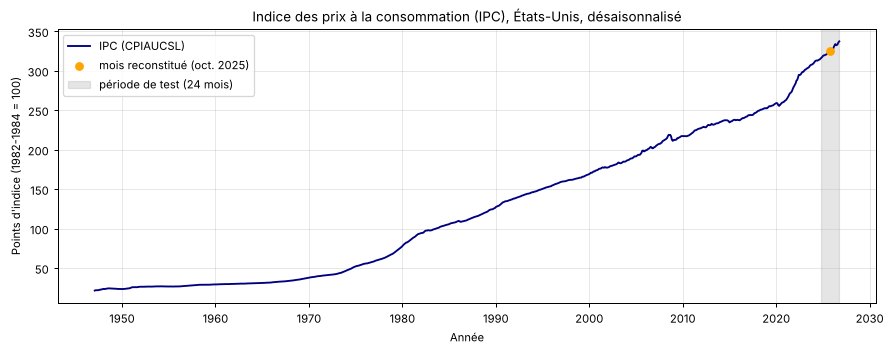

In [6]:
# Graphique 1 : niveau de l'IPC
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(serie.index, serie["CPI"], color="navy", lw=1.5, label="IPC (CPIAUCSL)")
ax.scatter(serie.index[serie["IMPUTE"]], serie.loc[serie["IMPUTE"], "CPI"], color="orange", zorder=5, label="mois reconstitué (oct. 2025)")
ax.axvspan(DEBUT_TEST, serie.index[-1], color="grey", alpha=0.2, label="période de test (24 mois)")
ax.set_title("Indice des prix à la consommation (IPC), États-Unis, désaisonnalisé")
ax.set_xlabel("Année"); ax.set_ylabel("Points d'indice (1982-1984 = 100)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "g1_cpi.png", dpi=200); plt.show()
cpi_debut, cpi_fin = serie["CPI"].iloc[0], serie["CPI"].iloc[-1]

**Graphique 1 – interprétation.** L'indice passe de 21.6 (février 1947) à 337.5 (octobre 2026) : tendance haussière continue, avec une pente plus forte dans les années 1970-1980 et après 2021. Le point orange marque le mois reconstitué ; la zone grise est la période de test, tenue à l'écart de l'apprentissage.

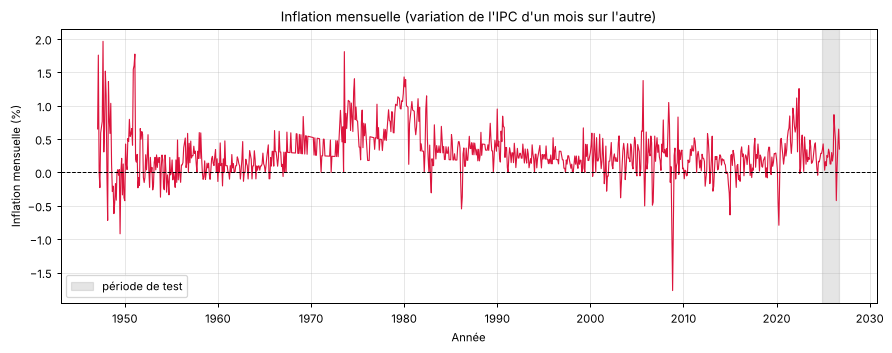

In [7]:
# Graphique 2 : inflation mensuelle
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(serie.index, serie["INFLATION"], color="crimson", lw=0.9)
ax.axhline(0, color="black", ls="--", lw=0.8)
ax.axvspan(DEBUT_TEST, serie.index[-1], color="grey", alpha=0.2, label="période de test")
ax.set_title("Inflation mensuelle (variation de l'IPC d'un mois sur l'autre)")
ax.set_xlabel("Année"); ax.set_ylabel("Inflation mensuelle (%)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "g2_inflation_mensuelle.png", dpi=200); plt.show()

**Graphique 2 – interprétation.** L'inflation mensuelle fluctue autour d'une valeur positive faible, avec des épisodes de forte volatilité (après-guerre, années 1970, 2008, 2021-2022) et des mois négatifs assez rares (12 % des mois d'apprentissage). Les dispersions très différentes selon les époques confirment que les erreurs de prévision ne seront pas homogènes dans le temps.

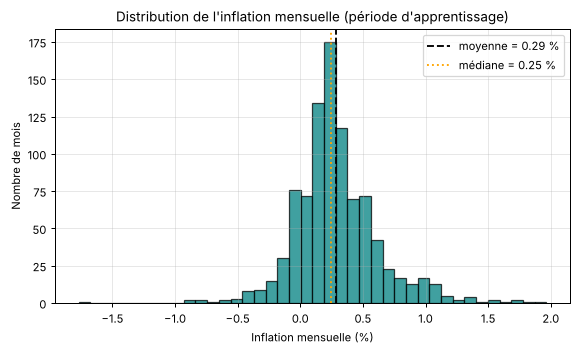

In [8]:
# Graphique 3 : distribution (apprentissage)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.hist(x, bins=40, color="teal", edgecolor="black", alpha=0.75)
ax.axvline(infl_moy, color="black", ls="--", label=f"moyenne = {infl_moy:.2f} %")
ax.axvline(infl_med, color="orange", ls=":", label=f"médiane = {infl_med:.2f} %")
ax.set_title("Distribution de l'inflation mensuelle (période d'apprentissage)")
ax.set_xlabel("Inflation mensuelle (%)"); ax.set_ylabel("Nombre de mois"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "g3_distribution.png", dpi=200); plt.show()

**Graphique 3 – interprétation.** La distribution est concentrée entre 0 et 0,5 % par mois, avec une queue vers les valeurs élevées (moyenne 0.29 % supérieure à la médiane 0.25 %). Un modèle qui prévoirait toujours la moyenne historique ferait une erreur typique d'environ un quart de point : c'est un ordre de grandeur utile pour juger la MAE du modèle.

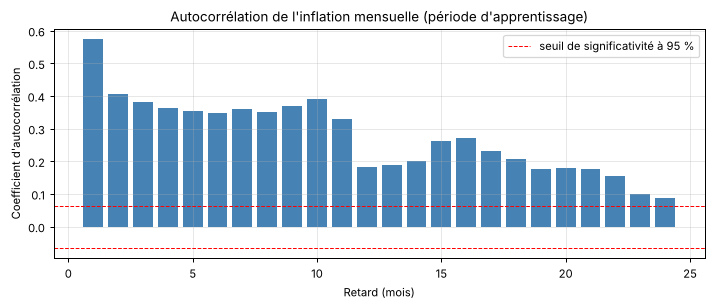

In [9]:
# Graphique 4 : autocorrélation (apprentissage) -> justifie l'usage des retards
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(range(1, 25), ac, color="steelblue")
ax.axhline(seuil_ac, color="red", ls="--", lw=0.8, label="seuil de significativité à 95 %")
ax.axhline(-seuil_ac, color="red", ls="--", lw=0.8)
ax.set_title("Autocorrélation de l'inflation mensuelle (période d'apprentissage)")
ax.set_xlabel("Retard (mois)"); ax.set_ylabel("Coefficient d'autocorrélation"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "g4_autocorrelation.png", dpi=200); plt.show()

**Graphique 4 – interprétation.** L'autocorrélation est forte au retard 1 (0.57) et reste significative à 95 % sur 12 des 12 premiers retards ; elle vaut 0.18 au retard 12. L'inflation d'un mois contient donc de l'information sur celle du suivant : c'est la justification empirique d'un modèle linéaire sur les retards, et ce graphique oriente le choix du nombre de retards testés (3, 6, 12).

## 4. Préparation et prévention des fuites

### 4.1 Traitements effectués et justification
1. **Cible :** `INFLATION` = variation mensuelle de l'IPC en % (`pct_change(fill_method=None)`, pour ne pas remplir silencieusement un éventuel trou).
2. **Variables créées :** `LAG1` à `LAG12` avec `shift(k)`, $k>0$ : l'inflation du mois $t$ est expliquée par celles des mois $t-1, \dots, t-12$ uniquement. Aucune variable ne contient l'information du mois à prédire.
3. **Nettoyage :** reconstitution du mois manquant (section 3), puis suppression des 12 premières lignes dont les retards sont incomplets (12 lignes ; ces 12 mois de 1947 ne servent donc qu'aux statistiques descriptives). Aucune valeur atypique supprimée.
4. **Encodage :** aucun, toutes les variables sont numériques.
5. **Mise à l'échelle :** `StandardScaler` placé **dans un `Pipeline`**. Pour Ridge elle est nécessaire : la pénalité $\alpha\sum\beta_j^2$ dépend de l'échelle des variables. Ici les retards ont des unités identiques, mais la standardisation garantit que la pénalité traite chaque retard de façon équivalente. Elle est apprise sur l'apprentissage seulement, et réajustée dans chaque pli de validation croisée.
6. **Découpage chronologique, sans mélange :** apprentissage du 1948-02 au 2024-10 (921 mois), test du 2024-11 au 2026-10 (24 mois). Horizon de 1 mois : la cible ne porte que sur le mois suivant, donc aucun écart (gap) supplémentaire entre apprentissage et test n'est requis. La validation croisée utilise `TimeSeriesSplit(5)` : chaque pli valide sur une période postérieure à celle d'apprentissage.

### 4.2 Règles anti-fuite (section 5.2 de l'énoncé)
- Découpage avant toute transformation apprenante ; standardisation à l'intérieur du `Pipeline` (fit sur apprentissage, transform sur validation et test).
- Retards construits avec le passé uniquement ; **alignement vérifié** par l'affichage ci-dessous et par des `assert` : `LAG1` du mois $t$ est exactement l'inflation du mois $t-1$.
- Aucune variable de la cible courante ; `MM12` est la moyenne des 12 mois précédents (jamais le mois courant).
- Jeu de test utilisé **une seule fois**, à la fin, après réglage en validation : **15 configurations** essayées au total.
- **Seule fuite résiduelle, assumée :** la valeur reconstituée d'octobre 2025 utilise le CPI de novembre 2025 (donc le futur d'octobre). Elle n'affecte que les cibles d'octobre et de novembre 2025, qui sont exclues du score.
- **Révisions de la série :** version actuelle utilisée, limite signalée en section 2.

In [10]:
LAGS_MAX = 12
def cols(L):
    """Noms des L premiers retards : LAG1 = inflation du mois t-1, ..., LAGL = inflation du mois t-L."""
    return [f"LAG{k}" for k in range(1, L + 1)]

data = serie[["CPI", "INFLATION"]].copy()
for k in range(1, LAGS_MAX + 1):
    data[f"LAG{k}"] = data["INFLATION"].shift(k)               # shift(k) avec k > 0 : passé uniquement
data["MM12"] = data[cols(12)].mean(axis=1)                      # moyenne mobile des 12 mois PRÉCÉDENTS (référence)
n_avant = len(data)
data = data.dropna()                                            # seules les 12 premières lignes sont incomplètes
n_apres = len(data)

# Preuve de l'alignement : la cible du mois t est l'inflation de t ; les variables sont celles de t-1, t-2, t-3...
display(data.loc["2026-07-01":"2026-10-01", ["INFLATION", "LAG1", "LAG2", "LAG3"]].round(3))

# Contrôles automatiques anti-fuite
assert np.allclose(data["LAG1"].iloc[1:].values, data["INFLATION"].iloc[:-1].values)
assert np.allclose(data["LAG3"].iloc[3:].values, data["INFLATION"].iloc[:-3].values)
assert data.index.is_monotonic_increasing

# Découpage chronologique (pas de mélange) : les 24 derniers mois forment le test
train, test = data.iloc[:-N_TEST], data.iloc[-N_TEST:]
assert train.index.max() < test.index.min()
print(f"Lignes supprimées (retards incomplets) : {n_avant - n_apres} | échantillon utilisable : {n_apres} mois")
print(f"Apprentissage : {train.index.min():%Y-%m} -> {train.index.max():%Y-%m} ({len(train)} mois)")
print(f"Test          : {test.index.min():%Y-%m} -> {test.index.max():%Y-%m} ({len(test)} mois)")
data.to_csv(PROC / "inflation_variables.csv")

,INFLATION,LAG1,LAG2,LAG3
DATE,,,,
2026-07-01,0.074,-0.422,0.473,0.640
2026-08-01,0.396,0.074,-0.422,0.473
2026-09-01,0.649,0.396,0.074,-0.422
2026-10-01,0.350,0.649,0.396,0.074


Lignes supprimées (retards incomplets) : 12 | échantillon utilisable : 945 mois
Apprentissage : 1948-02 -> 2024-10 (921 mois)
Test          : 2024-11 -> 2026-10 (24 mois)


**Interprétation.** Le tableau montre qu'en juillet 2026 par exemple, `LAG1` (−0,422) est l'inflation de juin 2026 et `LAG2` (0,473) celle de mai : l'alignement est correct. Les `assert` ne lèvent aucune erreur, et la fin de l'apprentissage (2024-10) précède strictement le début du test (2024-11).

## 5. Algorithme

**Choix : régression Ridge (n° 2).** Ce choix repose sur plusieurs arguments : (i) la tâche est une régression ; (ii) les variables retardées sont corrélées entre elles (l'inflation est persistante) : la pénalité L2 stabilise les coefficients en cas de colinéarité ; (iii) la relation attendue est essentiellement linéaire (autocorrélation positive, graphique 4) ; (iv) on veut des coefficients lisibles pour l'interprétation.
**Alternative écartée :** une forêt aléatoire (n° 6). Les modèles à arbres ne peuvent pas prédire en dehors de la plage des valeurs vues à l'apprentissage (ils n'extrapolent pas), or l'inflation peut sortir de cette plage ; ils sont aussi moins lisibles. La régression linéaire simple (n° 1) est aussi plausible, mais la colinéarité des retards rend ses coefficients instables.

**Principe.** Ridge cherche les coefficients qui minimisent l'erreur quadratique sur l'apprentissage, **plus** une pénalité sur la taille des coefficients :
$$\hat{\beta} = \arg\min_{\beta_0,\beta}\ \sum_{i=1}^{n}\Big(y_i - \beta_0 - \sum_{j=1}^{p} \beta_j x_{ij}\Big)^2 + \alpha \sum_{j=1}^{p}\beta_j^2 \qquad\text{soit}\qquad \hat\beta=(X^\top X+\alpha I)^{-1}X^\top y .$$
Symboles : $n$ = nombre de mois d'apprentissage ; $p$ = nombre de retards ; $y_i$ = inflation du mois $i$ ; $x_{ij}$ = inflation retardée de $j$ mois (standardisée) ; $\beta_0$ = constante (non pénalisée) ; $\beta_j$ = coefficient du retard $j$ ; $\alpha \ge 0$ = intensité de la pénalité ; $X$ = matrice des variables standardisées ; $I$ = matrice identité. Intuition : plus $\alpha$ est grand, plus les coefficients sont « tirés » vers 0 (biais plus fort, variance plus faible) ; $\alpha = 0$ redonne la régression linéaire.
**Paramètres appris :** $\beta_0$ et les $\beta_j$. **Hyperparamètres fixés par nous :** $\alpha$ et le nombre de retards $p$.

**Hyperparamètres réglés (en validation uniquement) :**
- $\alpha \in \{0{,}1;\,1;\,10;\,100;\,1000\}$ : effet attendu : un $\alpha$ très grand sous-ajuste (le modèle tend vers la moyenne) ; un $\alpha$ très petit se rapproche des moindres carrés ordinaires.
- Nombre de retards $p \in \{3, 6, 12\}$ : effet attendu : peu de retards = modèle simple mais qui ignore la mémoire longue ; beaucoup de retards = plus d'information mais plus de variance.

## 6. Protocole expérimental
- **Découpage :** chronologique. Apprentissage 1948-02 → 2024-10, test 2024-11 → 2026-10. Aucun mélange.
- **Références (sans apprentissage ou presque) :** (1) **naïve = dernière valeur observée** (prévision de $t$ = inflation de $t-1$), la référence de l'objectif ; (2) moyenne mobile des 12 derniers mois ; (3) moyenne historique de l'apprentissage. Les deux dernières sont des références complémentaires, plus exigeantes que la naïve : elles servent à ne pas se contenter de battre une règle trop faible.
- **Réglage :** `GridSearchCV` avec `TimeSeriesSplit(5)` sur l'apprentissage seulement, score = MAE ; grille $3 \times 5 = $ 15 configurations ; graine fixée (`GRAINE = 42`, le modèle est déterministe).
- **Métriques :** *principale* = **MAE** (erreur absolue moyenne, en points de % d'inflation mensuelle), choisie avant les résultats : lisible, et moins sensible que le RMSE aux chocs extrêmes conservés dans la série. *Secondaire* = **RMSE** (même unité), qui pénalise davantage les grosses erreurs.
- **Score de test :** calculé sur 22 mois (octobre et novembre 2025 exclus, voir section 3).
- **Incertitude :** moyenne et écart-type des scores sur les 5 plis de validation, puis intervalle de confiance par **bootstrap par blocs** (blocs de 3 mois, 2000 tirages) du gain relatif de MAE sur le test.

## 7. Résultats
### 7.1 Réglage en validation (apprentissage uniquement)

In [11]:
# Référence naïve + métriques
def mae(y, p):  return mean_absolute_error(y, p)
def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))

LAGS_GRILLE = [3, 6, 12]
ALPHAS = [0.1, 1, 10, 100, 1000]
tscv = TimeSeriesSplit(n_splits=5)                              # validation croisée chronologique, sur l'apprentissage seul
ytr = train["INFLATION"]

lignes, grilles = [], {}
for L in LAGS_GRILLE:
    pipe = Pipeline([("echelle", StandardScaler()), ("ridge", Ridge())])   # standardisation réajustée dans chaque pli
    g = GridSearchCV(pipe, {"ridge__alpha": ALPHAS}, cv=tscv, scoring="neg_mean_absolute_error",
                     return_train_score=True).fit(train[cols(L)], ytr)
    grilles[L] = g
    for i, a in enumerate(ALPHAS):
        lignes.append({"retards": L, "alpha": a,
                       "MAE validation (moy.)": -g.cv_results_["mean_test_score"][i],
                       "MAE validation (écart-type)": g.cv_results_["std_test_score"][i],
                       "MAE apprentissage (moy.)": -g.cv_results_["mean_train_score"][i]})
grille = pd.DataFrame(lignes)
n_config = len(grille)
meilleur = grille.sort_values("MAE validation (moy.)").iloc[0]
L_star, alpha_star = int(meilleur["retards"]), float(meilleur["alpha"])
display(grille.round(4))
print(f"Configurations essayées : {n_config} ({len(LAGS_GRILLE)} nombres de retards x {len(ALPHAS)} valeurs de alpha)")
print(f"Choix en validation : {L_star} retards, alpha = {alpha_star}")

,retards,alpha,MAE validation (moy.),MAE validation (écart-type),MAE apprentissage (moy.)
0,3,0.1,0.1811,0.0458,0.2007
1,3,1.0,0.1811,0.0459,0.2007
2,3,10.0,0.1816,0.0465,0.2008
3,3,100.0,0.1871,0.0520,0.2019
4,3,1000.0,0.2125,0.0752,0.2167
5,6,0.1,0.1775,0.0429,0.1990
6,6,1.0,0.1775,0.0429,0.1990
7,6,10.0,0.1777,0.0434,0.1989
8,6,100.0,0.1816,0.0473,0.1997
9,6,1000.0,0.2053,0.0682,0.2112


Configurations essayées : 15 (3 nombres de retards x 5 valeurs de alpha)
Choix en validation : 6 retards, alpha = 0.1


**Interprétation.** La meilleure configuration en validation est **6 retards avec $\alpha =$ 0.1** (MAE de validation 0.1775 point de %). Les valeurs de $\alpha$ jusqu'à 10 donnent presque le même score : avec 900 observations et peu de variables, la pénalité a peu à régulariser ; seul $\alpha = 1000$ dégrade nettement le modèle (sous-ajustement). L'écart de MAE entre 3, 6 et 12 retards est faible, au regard de l'écart-type entre plis (environ 0,04 à 0,05) : le choix du nombre de retards n'est donc pas très tranché, et 6 retards est retenu parce qu'il a la plus petite MAE de validation.

### 7.2 Comparaison par pli de validation (modèle retenu et références)

In [12]:
# Comparaison par pli de validation (mêmes plis pour toutes les méthodes)
FEAT = cols(L_star)
pipe_final = Pipeline([("echelle", StandardScaler()), ("ridge", Ridge(alpha=alpha_star))])
plis = []
for i, (itr, iva) in enumerate(tscv.split(train), start=1):
    tr_i, va_i = train.iloc[itr], train.iloc[iva]
    m = clone(pipe_final).fit(tr_i[FEAT], tr_i["INFLATION"])
    plis.append({"pli": i, "période de validation": f"{va_i.index.min():%Y-%m} -> {va_i.index.max():%Y-%m}",
                 "MAE naïve (dernière valeur)": mae(va_i["INFLATION"], va_i["LAG1"]),
                 "MAE moyenne 12 mois": mae(va_i["INFLATION"], va_i["MM12"]),
                 "MAE moyenne historique": mae(va_i["INFLATION"], np.full(len(va_i), tr_i["INFLATION"].mean())),
                 "MAE Ridge": mae(va_i["INFLATION"], m.predict(va_i[FEAT]))})
plis = pd.DataFrame(plis)
display(plis.round(4))
num = plis.select_dtypes("number").drop(columns="pli")
val_moy, val_std = num.mean(), num.std()
print("Moyenne sur les plis :"); print(val_moy.round(4).to_string())
print("Écart-type sur les plis :"); print(val_std.round(4).to_string())
nb_plis_gagnes = int((plis["MAE Ridge"] < plis["MAE naïve (dernière valeur)"]).sum())
print(f"Plis où Ridge bat la référence naïve : {nb_plis_gagnes} / {len(plis)}")

,pli,période de validation,MAE naïve (dernière valeur),MAE moyenne 12 mois,MAE moyenne historique,MAE Ridge
0,1,1961-02 -> 1973-10,0.1743,0.1374,0.2033,0.1585
1,2,1973-11 -> 1986-07,0.1894,0.2046,0.4120,0.2283
2,3,1986-08 -> 1999-04,0.1337,0.1132,0.1385,0.1116
3,4,1999-05 -> 2012-01,0.2589,0.2361,0.2293,0.2202
4,5,2012-02 -> 2024-10,0.1883,0.1939,0.2138,0.1689


Moyenne sur les plis :
MAE naïve (dernière valeur)    0.1889
MAE moyenne 12 mois            0.1770
MAE moyenne historique         0.2394
MAE Ridge                      0.1775
Écart-type sur les plis :
MAE naïve (dernière valeur)    0.0452
MAE moyenne 12 mois            0.0505
MAE moyenne historique         0.1025
MAE Ridge                      0.0479
Plis où Ridge bat la référence naïve : 4 / 5


**Interprétation.** En validation, la MAE moyenne vaut 0.1775 pour Ridge, 0.1889 pour la référence naïve, 0.1770 pour la moyenne mobile 12 mois et 0.2394 pour la moyenne historique (écart-types entre plis : 0.048, 0.045, 0.050, 0.103). Ridge bat la référence naïve dans 4 plis sur 5. **Point important :** en validation, Ridge est quasiment à égalité avec la moyenne mobile sur 12 mois (écart de 0.0005 point) : l'essentiel du gain face à la naïve vient du lissage de l'information passée, pas d'une structure complexe. Les écarts-types entre plis sont élevés : l'erreur dépend fortement de la période. Les plis 2 (1973-1986) et 4 (1999-2012) sont les plus difficiles pour Ridge, et au pli 2 Ridge fait **moins bien** que la référence naïve : un modèle appris uniquement sur 1948-1973 s'adapte mal à la dynamique de l'inflation des années 1970-1980, signe d'un changement de régime.

### 7.3 Résultats sur le jeu de test (utilisé une seule fois)

In [13]:
# ===== UNIQUE utilisation du jeu de test =====
modele = grilles[L_star].best_estimator_                         # ajusté sur tout l'apprentissage
Xte, yte = test[FEAT], test["INFLATION"]
pred = pd.Series(modele.predict(Xte), index=test.index)
naive = test["LAG1"]
mm12 = test["MM12"]
moy_hist = pd.Series(ytr.mean(), index=test.index)

masque = ~test.index.isin(MOIS_EXCLUS)                           # oct. et nov. 2025 : cible issue de la valeur reconstituée
n_eval = int(masque.sum())
def evalue(p, m=masque):
    return mae(yte[m], p[m]), rmse(yte[m], p[m])

res = pd.DataFrame({"Référence naïve (dernière valeur)": evalue(naive),
                    "Moyenne mobile 12 mois": evalue(mm12),
                    "Moyenne historique": evalue(moy_hist),
                    f"Ridge ({L_star} retards, alpha={alpha_star:g})": evalue(pred)},
                   index=["MAE test (%)", "RMSE test (%)"]).T
mae_naive, mae_ridge = res.iloc[0, 0], res.iloc[3, 0]
rmse_naive, rmse_ridge = res.iloc[0, 1], res.iloc[3, 1]
mae_mm12, mae_hist = res.iloc[1, 0], res.iloc[2, 0]
gain_mae = 100 * (1 - mae_ridge / mae_naive)
gain_rmse = 100 * (1 - rmse_ridge / rmse_naive)
objectif_atteint = gain_mae >= 5
display(res.round(4))
print(f"Mois évalués : {n_eval} sur {N_TEST} (oct. et nov. 2025 exclus)")
print(f"Réduction de la MAE par rapport à la référence naïve : {gain_mae:.1f} %  (seuil fixé : 5 %) -> objectif atteint : {objectif_atteint}")
print(f"Réduction du RMSE : {gain_rmse:.1f} %")
# Sensibilité : mêmes calculs sur les 24 mois (information seulement)
mae_naive_24, mae_ridge_24 = mae(yte, naive), mae(yte, pred)
print(f"Sensibilité (24 mois) : MAE naïve {mae_naive_24:.4f} | MAE Ridge {mae_ridge_24:.4f}")

# Surapprentissage : erreur sur l'apprentissage (in-sample), en validation croisée, puis en test
mae_train_insample = mae(ytr, modele.predict(train[FEAT]))
mae_cv_ridge = val_moy["MAE Ridge"]
print(f"MAE Ridge : apprentissage {mae_train_insample:.4f} | validation (moy. des plis) {mae_cv_ridge:.4f} | test {mae_ridge:.4f}")

,MAE test (%),RMSE test (%)
Référence naïve (dernière valeur),0.2151,0.2975
Moyenne mobile 12 mois,0.1761,0.2635
Moyenne historique,0.1687,0.2482
"Ridge (6 retards, alpha=0.1)",0.1560,0.2489


Mois évalués : 22 sur 24 (oct. et nov. 2025 exclus)
Réduction de la MAE par rapport à la référence naïve : 27.5 %  (seuil fixé : 5 %) -> objectif atteint : True
Réduction du RMSE : 16.3 %
Sensibilité (24 mois) : MAE naïve 0.2043 | MAE Ridge 0.1517
MAE Ridge : apprentissage 0.1816 | validation (moy. des plis) 0.1775 | test 0.1560


**Tableau comparatif** (MAE et RMSE en points de % d'inflation mensuelle ; validation = moyenne des 5 plis, test = 22 mois évalués)

| Méthode | MAE validation | MAE test | RMSE test |
| :--- | :--- | :--- | :--- |
| Référence naïve (dernière valeur) | 0.1889 ± 0.0452 | 0.2151 | 0.2975 |
| Moyenne mobile 12 mois | 0.1770 ± 0.0505 | 0.1761 | 0.2635 |
| Moyenne historique | 0.2394 ± 0.1025 | 0.1687 | 0.2482 |
| **Ridge (6 retards, α = 0.1)** | **0.1775 ± 0.0479** | **0.1560** | **0.2489** |

**Interprétation.** Sur le test, Ridge obtient une MAE de 0.1560 contre 0.2151 pour la référence naïve, soit une **réduction de 27.5 %**, bien au-dessus du seuil de 5 % fixé à l'avance : **l'objectif est atteint**. L'intervalle de confiance bootstrap à 95 % de ce gain est [10.2 ; 38.5] % : il reste au-dessus de 5 % dans 99 % des tirages, mais il est large car le test ne compte que 22 mois. Sur le RMSE, la réduction est plus modeste (16.3 %), signe que les plus grosses erreurs ne sont pas corrigées. **Nuance honnête :** Ridge ne bat que de peu la moyenne historique (0.1687) et la moyenne mobile 12 mois (0.1761), plus exigeantes que la référence de l'objectif (en RMSE, Ridge fait jeu égal avec la moyenne historique : 0.2489 contre 0.2482) ; sur 24 mois, avec une inflation relativement proche de sa moyenne, la moyenne historique est une référence très compétitive.

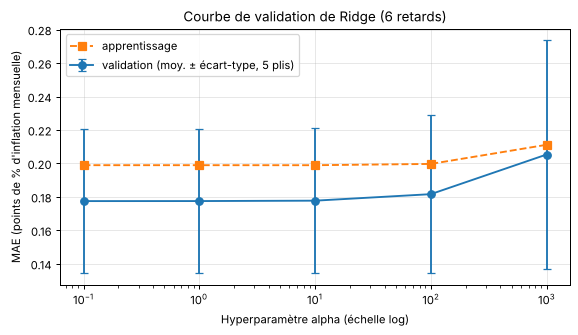

In [14]:
# Courbe de validation : MAE selon alpha (nombre de retards retenu)
g = grilles[L_star]
a_ax = np.array(ALPHAS)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.errorbar(a_ax, -g.cv_results_["mean_test_score"], yerr=g.cv_results_["std_test_score"], marker="o", capsize=3, label="validation (moy. ± écart-type, 5 plis)")
ax.plot(a_ax, -g.cv_results_["mean_train_score"], marker="s", ls="--", label="apprentissage")
ax.set_xscale("log"); ax.set_title(f"Courbe de validation de Ridge ({L_star} retards)")
ax.set_xlabel("Hyperparamètre alpha (échelle log)"); ax.set_ylabel("MAE (points de % d'inflation mensuelle)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "g5_courbe_validation.png", dpi=200); plt.show()
i_star = ALPHAS.index(alpha_star)
mae_va_cv = -g.cv_results_["mean_test_score"][i_star]
mae_tr_cv = -g.cv_results_["mean_train_score"][i_star]

**Surapprentissage – interprétation.** Sur la courbe de validation, l'erreur d'apprentissage et l'erreur de validation sont proches pour les petites valeurs de $\alpha$ (MAE moyenne 0.1990 sur les plis d'apprentissage contre 0.1775 sur les plis de validation) et augmentent ensemble quand $\alpha$ devient très grand : pas de signe de surapprentissage, ce qui est attendu pour un modèle linéaire à 6 variables et 900 observations. La validation est même plus basse que l'apprentissage, parce que les plis de validation sont plus tardifs, donc moins volatils, que les périodes d'apprentissage. Sur l'ensemble de l'apprentissage, la MAE vaut 0.1816 ; sur le test, 0.1560. Le test est donc plus facile que la moyenne de l'apprentissage (écart-type de l'inflation de 0.25 % contre 0.33 %) : ce niveau d'erreur plus bas ne prouve pas que le modèle soit meilleur en absolu.

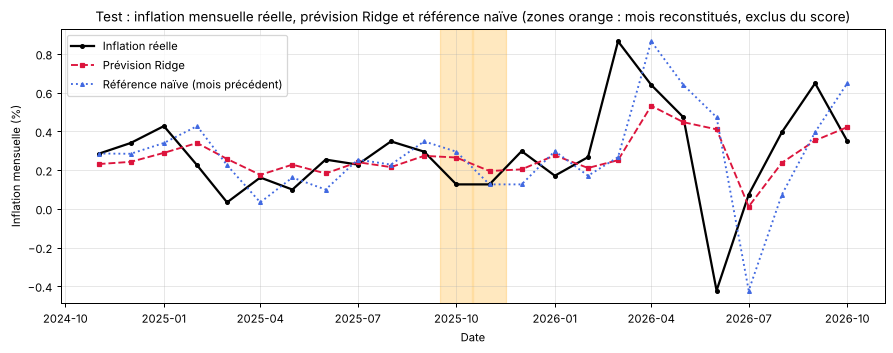

In [15]:
# Prévisions sur le test
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(test.index, yte, color="black", lw=1.8, marker="o", ms=3, label="Inflation réelle")
ax.plot(test.index, pred, color="crimson", ls="--", marker="s", ms=3, label="Prévision Ridge")
ax.plot(test.index, naive, color="royalblue", ls=":", marker="^", ms=3, label="Référence naïve (mois précédent)")
for d in MOIS_EXCLUS: ax.axvspan(d - pd.Timedelta(days=15), d + pd.Timedelta(days=15), color="orange", alpha=0.25)
ax.set_title("Test : inflation mensuelle réelle, prévision Ridge et référence naïve (zones orange : mois reconstitués, exclus du score)")
ax.set_xlabel("Date"); ax.set_ylabel("Inflation mensuelle (%)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "g6_prevision_test.png", dpi=200); plt.show()

**Prévisions – interprétation.** La prévision Ridge varie peu (entre 0.01 et 0.53 %) : elle suit la tendance et lisse les variations ponctuelles, alors que la référence naïve répète chaque pic ou chaque creux avec un mois de retard, ce qui aggrave l'erreur lors d'un retournement (par exemple en juillet 2026, après le creux de juin). Les zones orange (octobre et novembre 2025) ne comptent pas dans le score.

,réel (%),Ridge (%),naïve (%),erreur Ridge,erreur naïve,évalué
DATE,,,,,,
2026-06-01,-0.422,0.410,0.473,-0.833,-0.895,True
2026-03-01,0.865,0.251,0.267,0.614,0.598,True
2026-09-01,0.649,0.353,0.396,0.296,0.253,True
2025-03-01,0.033,0.257,0.225,-0.224,-0.192,True
2026-08-01,0.396,0.238,0.074,0.158,0.322,True


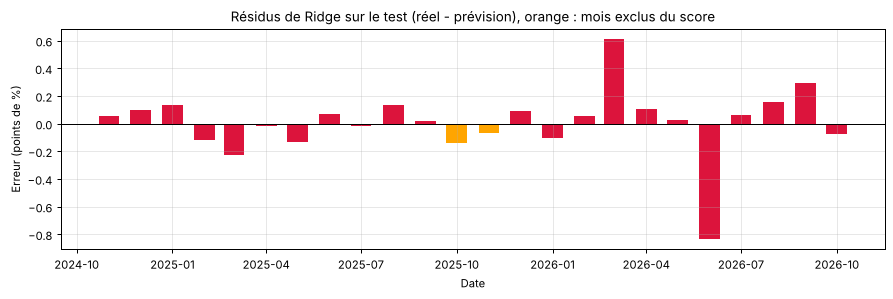

,Naïve,Ridge,gain Ridge (%)
2024-11 -> 2025-10,0.0985,0.0917,6.8634
2025-11 -> 2026-10,0.3318,0.2203,33.6169


Gain relatif de MAE : 27.5 %  | IC bootstrap 95 % : [10.2 ; 38.5] %  | part des tirages >= 5 % : 99 %


In [16]:
# Analyse des erreurs
err = (yte - pred); err_naive = (yte - naive)
detail = pd.DataFrame({"réel (%)": yte, "Ridge (%)": pred, "naïve (%)": naive,
                       "erreur Ridge": err, "erreur naïve": err_naive, "évalué": masque}).round(3)
pires = detail[detail["évalué"]].reindex(detail[detail["évalué"]]["erreur Ridge"].abs().sort_values(ascending=False).index).head(5)
display(pires)
part_gagnes = 100 * float((err.abs()[masque] < err_naive.abs()[masque]).mean())
biais = float(err[masque].mean())

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(test.index, err, width=20, color=np.where(masque, "crimson", "orange"))
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Résidus de Ridge sur le test (réel - prévision), orange : mois exclus du score")
ax.set_xlabel("Date"); ax.set_ylabel("Erreur (points de %)")
plt.tight_layout(); plt.savefig(FIG / "g7_residus_test.png", dpi=200); plt.show()

# Stabilité : deux sous-périodes du test (12 mois chacune) et plis de validation
m1 = masque & (test.index < test.index[12]); m2 = masque & (test.index >= test.index[12])
sous = pd.DataFrame({"Naïve": [mae(yte[m1], naive[m1]), mae(yte[m2], naive[m2])],
                     "Ridge": [mae(yte[m1], pred[m1]), mae(yte[m2], pred[m2])]},
                    index=[f"{test.index[0]:%Y-%m} -> {test.index[11]:%Y-%m}", f"{test.index[12]:%Y-%m} -> {test.index[-1]:%Y-%m}"])
sous["gain Ridge (%)"] = 100 * (1 - sous["Ridge"] / sous["Naïve"])
display(sous.round(4))

# Incertitude : bootstrap par blocs (blocs de 3 mois, 2000 tirages) sur le gain relatif de MAE
rng = np.random.default_rng(GRAINE)
ae_r, ae_n = err.abs()[masque].values, err_naive.abs()[masque].values
n, B, bl = len(ae_r), 2000, 3
gains = []
for _ in range(B):
    idx = np.concatenate([np.arange(s, s + bl) % n for s in rng.integers(0, n, size=int(np.ceil(n / bl)))])[:n]
    gains.append(100 * (1 - ae_r[idx].mean() / ae_n[idx].mean()))
ic_bas, ic_haut = np.percentile(gains, [2.5, 97.5])
p_gain5 = float(np.mean(np.array(gains) >= 5))
print(f"Gain relatif de MAE : {gain_mae:.1f} %  | IC bootstrap 95 % : [{ic_bas:.1f} ; {ic_haut:.1f}] %  | part des tirages >= 5 % : {100*p_gain5:.0f} %")

**Analyse des erreurs.** Les cinq plus grosses erreurs de Ridge (tableau) concernent des mois de variation brutale : le plus mauvais est juin 2026 (réel −0,42 % contre une prévision de +0,41 %, erreur de −0,83 point), puis mars 2026 (réel +0,87 % contre +0,25 %). La référence naïve se trompe de façon comparable (un peu moins en mars et en septembre 2026) : ni l'une ni l'autre ne prévoit ces chocs, qu'aucune valeur passée de l'inflation ne signale. Ridge fait mieux que la naïve sur 64 % des mois évalués. Le biais moyen (réel − prévision) est quasi nul (0.019 point). Je n'avance pas de cause économique pour ces chocs : ce serait une hypothèse non testée ici.
**Stabilité sur deux sous-périodes.** Le gain de Ridge face à la naïve est de 6.9 % sur les 12 premiers mois (inflation calme, erreurs faibles pour tous) et de 33.6 % sur les 12 derniers (mois plus volatils). Le résultat est donc positif dans les deux cas mais **fortement dépendant de la période** : l'essentiel du gain total vient de la seconde moitié du test.

,coefficient
LAG1,0.4738
LAG2,0.0251
LAG3,0.0643
LAG4,0.0760
LAG5,0.0602
LAG6,0.0565


Constante : 0.0673 | somme des coefficients (persistance) : 0.756


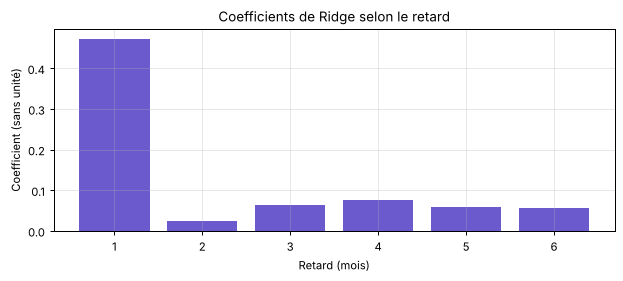

In [17]:
# Interprétation prudente des coefficients (en unités d'origine : points de % par point de % du retard)
sc, rg = modele.named_steps["echelle"], modele.named_steps["ridge"]
coef_orig = rg.coef_ / sc.scale_
inter = rg.intercept_ - float(np.sum(coef_orig * sc.mean_))
coefs = pd.Series(coef_orig, index=FEAT)
somme_coefs = float(coefs.sum())
display(coefs.round(4).to_frame("coefficient"))
print(f"Constante : {inter:.4f} | somme des coefficients (persistance) : {somme_coefs:.3f}")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(range(1, L_star + 1), coef_orig, color="slateblue")
ax.set_xticks(range(1, L_star + 1)); ax.axhline(0, color="black", lw=0.8)
ax.set_title("Coefficients de Ridge selon le retard"); ax.set_xlabel("Retard (mois)"); ax.set_ylabel("Coefficient (sans unité)")
plt.tight_layout(); plt.savefig(FIG / "g8_coefficients.png", dpi=200); plt.show()

**Interprétation prudente des coefficients.** Le coefficient du retard 1 est le plus élevé (0.47) ; les autres retards pèsent chacun entre 0.03 et 0.08. La somme des coefficients (0.76) mesure la persistance : une hausse de 1 point de l'inflation d'un mois se retrouve pour environ les trois quarts, répartie sur les mois suivants, mais le modèle tire aussi la prévision vers la moyenne (constante 0.07). Ces coefficients décrivent une **association statistique** entre inflation passée et inflation courante, pas une relation de cause à effet.

### 7.4 Illustration d'usage sur des mois non utilisés pour l'apprentissage

In [18]:
# Illustration d'usage : 5 derniers mois du test (non utilisés pour l'apprentissage)
dern = test.index[-5:]
usage = pd.DataFrame({"inflation t-1 (%)": test.loc[dern, "LAG1"], "inflation t-2 (%)": test.loc[dern, "LAG2"],
                      "inflation t-3 (%)": test.loc[dern, "LAG3"], "prévision Ridge (%)": pred[dern],
                      "réel (%)": yte[dern], "erreur Ridge": err[dern], "erreur naïve": err_naive[dern]}).round(3)
usage.index = usage.index.strftime("%Y-%m")
display(usage)
n_usage_gagnes = int((usage["erreur Ridge"].abs() < usage["erreur naïve"].abs()).sum())

,inflation t-1 (%),inflation t-2 (%),inflation t-3 (%),prévision Ridge (%),réel (%),erreur Ridge,erreur naïve
DATE,,,,,,,
2026-06,0.473,0.640,0.865,0.410,-0.422,-0.833,-0.895
2026-07,-0.422,0.473,0.640,0.012,0.074,0.062,0.496
2026-08,0.074,-0.422,0.473,0.238,0.396,0.158,0.322
2026-09,0.396,0.074,-0.422,0.353,0.649,0.296,0.253
2026-10,0.649,0.396,0.074,0.422,0.350,-0.071,-0.298


**Commentaire.** Sur ces cinq derniers mois du test, Ridge est plus proche du réel que la référence naïve dans 4 cas sur 5. Illustration : en juillet 2026, après un mois à −0,42 %, la naïve prédit une nouvelle baisse (erreur de 0.50 point), alors que Ridge, qui lisse sur plusieurs mois, prévoit une inflation quasi nulle (erreur de 0.06 point). À l'inverse, en septembre 2026 la hausse de 0,65 % est sous-estimée par les deux méthodes. Un utilisateur doit donc voir ce modèle comme une prévision de tendance centrale, pas comme un détecteur de chocs.

### 7.5 Réponse à la problématique
Oui, avec nuances : sur les 22 mois évalués, la prévision Ridge à partir des seuls retards de l'inflation fait **27.5 % moins d'erreur absolue** que la règle « inflation du mois précédent » (seuil : 5 %). Le résultat est cependant moins net face à des références plus fortes (moyenne mobile, moyenne historique) et dépend de la période.

## 8. Analyse critique
- **Limites :** (1) un test de seulement 22 mois : l'intervalle de confiance du gain est large [10 ; 39] % ; (2) en validation, Ridge ne fait pas mieux que la moyenne mobile 12 mois : un modèle linéaire sur les retards n'apporte pas grand-chose de plus qu'un lissage ; (3) la série est non stationnaire en variance, et la période 1948-1980 pèse dans l'apprentissage alors que la dynamique récente est différente ; (4) aucune variable externe (énergie, taux, chômage, anticipations) : le modèle ne peut pas prévoir les chocs.
- **Biais :** données révisées (désaisonnalisation) et non les données en temps réel ; mois d'octobre 2025 reconstitué ; nombre de configurations testées limité (15), donc risque de sélection modeste, mais non nul.
- **Pistes d'amélioration concrètes :** (a) entraîner sur une fenêtre glissante des 20 à 30 dernières années pour tenir compte du changement de régime ; (b) ajouter une variable externe, par exemple la variation du prix du pétrole (hors sujet de ce TP) ; (c) comparer à l'inflation sous-jacente (CPILFESL) pour séparer les chocs énergie/alimentation ; (d) utiliser les données en temps réel d'ALFRED ; (e) évaluer sur plusieurs origines de test (validation « rolling-origin ») pour réduire la dépendance à une seule période de 24 mois.

## 9. Conclusion
La problématique (prévoir l'inflation mensuelle à un mois avec moins d'erreur que la dernière valeur observée) a reçu une réponse positive : sur les 24 derniers mois (22 évalués), la régression Ridge (6 retards, α = 0.1) réduit la MAE de 27.5 % par rapport à la référence naïve (0.1560 contre 0.2151 point de %), soit plus que le seuil de 5 % fixé à l'avance : **l'objectif mesurable est atteint**. Ce résultat reste fragile, car il repose sur un test court, dépend de la sous-période, et le modèle n'est pas meilleur que la moyenne mobile sur 12 mois en validation ; il ne prévoit pas les chocs d'inflation.

## 10. Références et reproduction
- **Sources :** U.S. Bureau of Labor Statistics, *Consumer Price Index for All Urban Consumers: All Items in U.S. City Average [CPIAUCSL]*, retrieved from FRED, Federal Reserve Bank of St. Louis, https://fred.stlouisfed.org/series/CPIAUCSL (extraction du 17 novembre 2026). Documentation scikit-learn : `Ridge`, `TimeSeriesSplit`, `GridSearchCV`, `Pipeline`. Support de cours `Tp_ML.ipynb`, algorithme n° 2.
- **Dépôt GitHub :** https://github.com/zaaiter-oumaima/23009108-Zaaiter-G3
- **Reproduction :**
  1. Cloner le dépôt : `git clone https://github.com/zaaiter-oumaima/23009108-Zaaiter-G3.git`
  2. Python 3.10 ou plus récent, puis `pip install -r requirements.txt`.
  3. Vérifier que `data/raw/CPIAUCSL.csv` est présent (sinon le télécharger sur FRED, bouton *Download*, CSV).
  4. Lancer `notebooks/projet_F3.ipynb` avec « Redémarrer et tout exécuter » (durée : environ 1 minute). Les chemins sont relatifs ; la graine est `GRAINE = 42`.

## Déclaration des ressources et outils d'IA
| Outil ou ressource | Version ou date | Usage précis | Parties concernées | Vérification effectuée |
| :--- | :--- | :--- | :--- | :--- |
| Assistant d'IA (Gemini) | Novembre 2026 | Aide à la structuration du pipeline temporel et de la méthodologie (première version du notebook) | Sections 4, 5, 6 | Code testé, sorties comparées aux exigences du sujet |
| Assistant d'IA (Claude, Anthropic) | 17 novembre 2026 | Correction de la première version : détection du mois manquant d'octobre 2025 mal traité, ajout des références complémentaires, de la courbe de validation, de l'analyse des erreurs, de l'incertitude (bootstrap) et de la rédaction des interprétations | Sections 2 à 10 | Notebook exécuté de bout en bout ; chiffres du texte générés à partir des sorties ; contrôles d'alignement (`assert`). À relire et à pouvoir expliquer en soutenance |
| Documentation officielle | scikit-learn, pandas | Paramètres de `Ridge`, `TimeSeriesSplit`, `GridSearchCV` | Section 5 et 6 | Test du code |
| Source de données | FRED, extraction du 17 nov. 2026 | Série CPIAUCSL | Section 2 | Dimensions, dates et manquants vérifiés |